In [2]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Database connection
conn = sqlite3.connect('../data/olist_ecommerce.db')

# loading final table 
df = pd.read_sql("SELECT * FROM seller_summary", conn)

print(" Data Loaded!")
print(f"Shape: {df.shape}")
print(f"\nColumns:")
for col in df.columns:
    print(f"  - {col}")

 Data Loaded!
Shape: (2965, 17)

Columns:
  - seller_id
  - seller_city
  - seller_state
  - total_orders
  - total_revenue
  - total_freight_cost
  - avg_order_value
  - avg_rating
  - total_reviews
  - late_deliveries
  - late_delivery_pct
  - top_category
  - gross_profit
  - profit_margin
  - revenue_per_order
  - performance_label
  - delivery_status


In [3]:
print(df.describe().T)
# missing values
missing = df.isnull().sum()
missing = missing[missing>0]
if len(missing)== 0:
    print("no missing value")
else:
    print(missing)


                     count         mean           std     min     25%     50%  \
total_orders        2965.0    32.768634    104.783507    1.00    2.00    7.00   
total_revenue       2965.0  4441.258722  13895.720297    6.50  219.90  847.78   
total_freight_cost  2965.0   739.599663   2338.505918    0.75   50.67  161.83   
avg_order_value     2965.0   175.594675    323.626034    6.00   52.46   95.50   
avg_rating          2965.0     4.150793      0.797062    1.00    3.90    4.27   
total_reviews       2965.0    37.103879    119.826018    1.00    2.00    8.00   
late_deliveries     2965.0     2.887015     10.394791    0.00    0.00    0.00   
late_delivery_pct   2965.0     9.537737     21.375573    0.00    0.00    0.00   
gross_profit        2965.0  3701.659059  11999.616254 -559.76  154.36  656.10   
profit_margin       2965.0    73.620715     22.534549 -253.50   67.40   79.48   
revenue_per_order   2965.0   194.088813    348.771040    6.00   60.20  106.25   

                        75%

# DISTRIBUTION plots

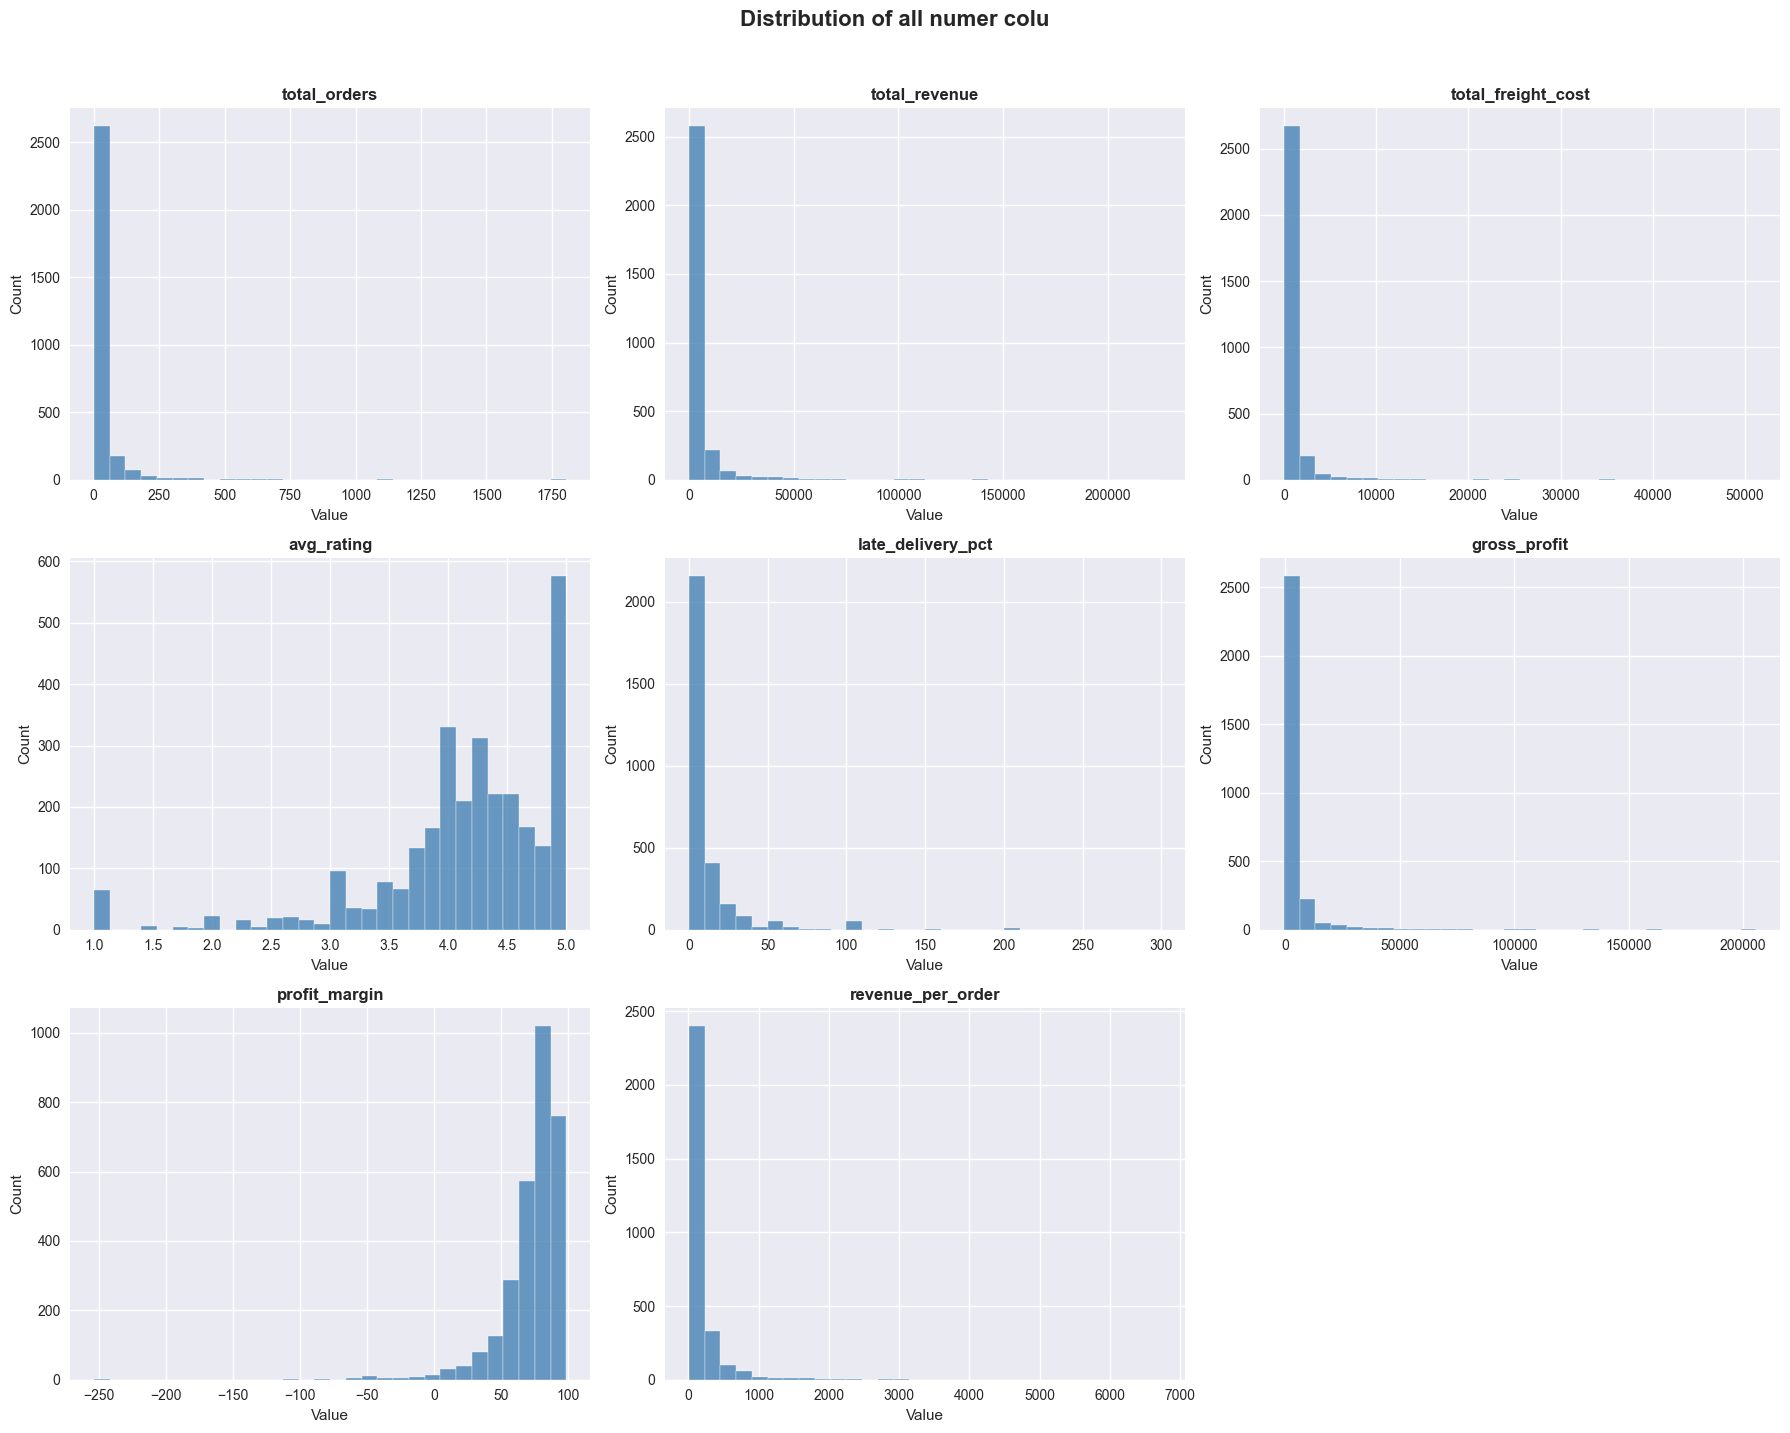

Plot saved in reports/ folder!


In [4]:
numerical_cols = [
    'total_orders', 'total_revenue', 'total_freight_cost',
    'avg_rating', 'late_delivery_pct', 'gross_profit',
    'profit_margin', 'revenue_per_order'
]

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    axes[idx].hist(df[col], bins=30, color='steelblue', 
                   edgecolor='white', alpha=0.8)
    axes[idx].set_title(f'{col}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Value')
    axes[idx].set_ylabel('Count')


axes[-1].set_visible(False)

plt.suptitle('Distribution of all numer colu', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/01_distributions.png', 
            bbox_inches='tight', dpi=150)
plt.show()
print("Plot saved in reports/ folder!")

# BOX plots

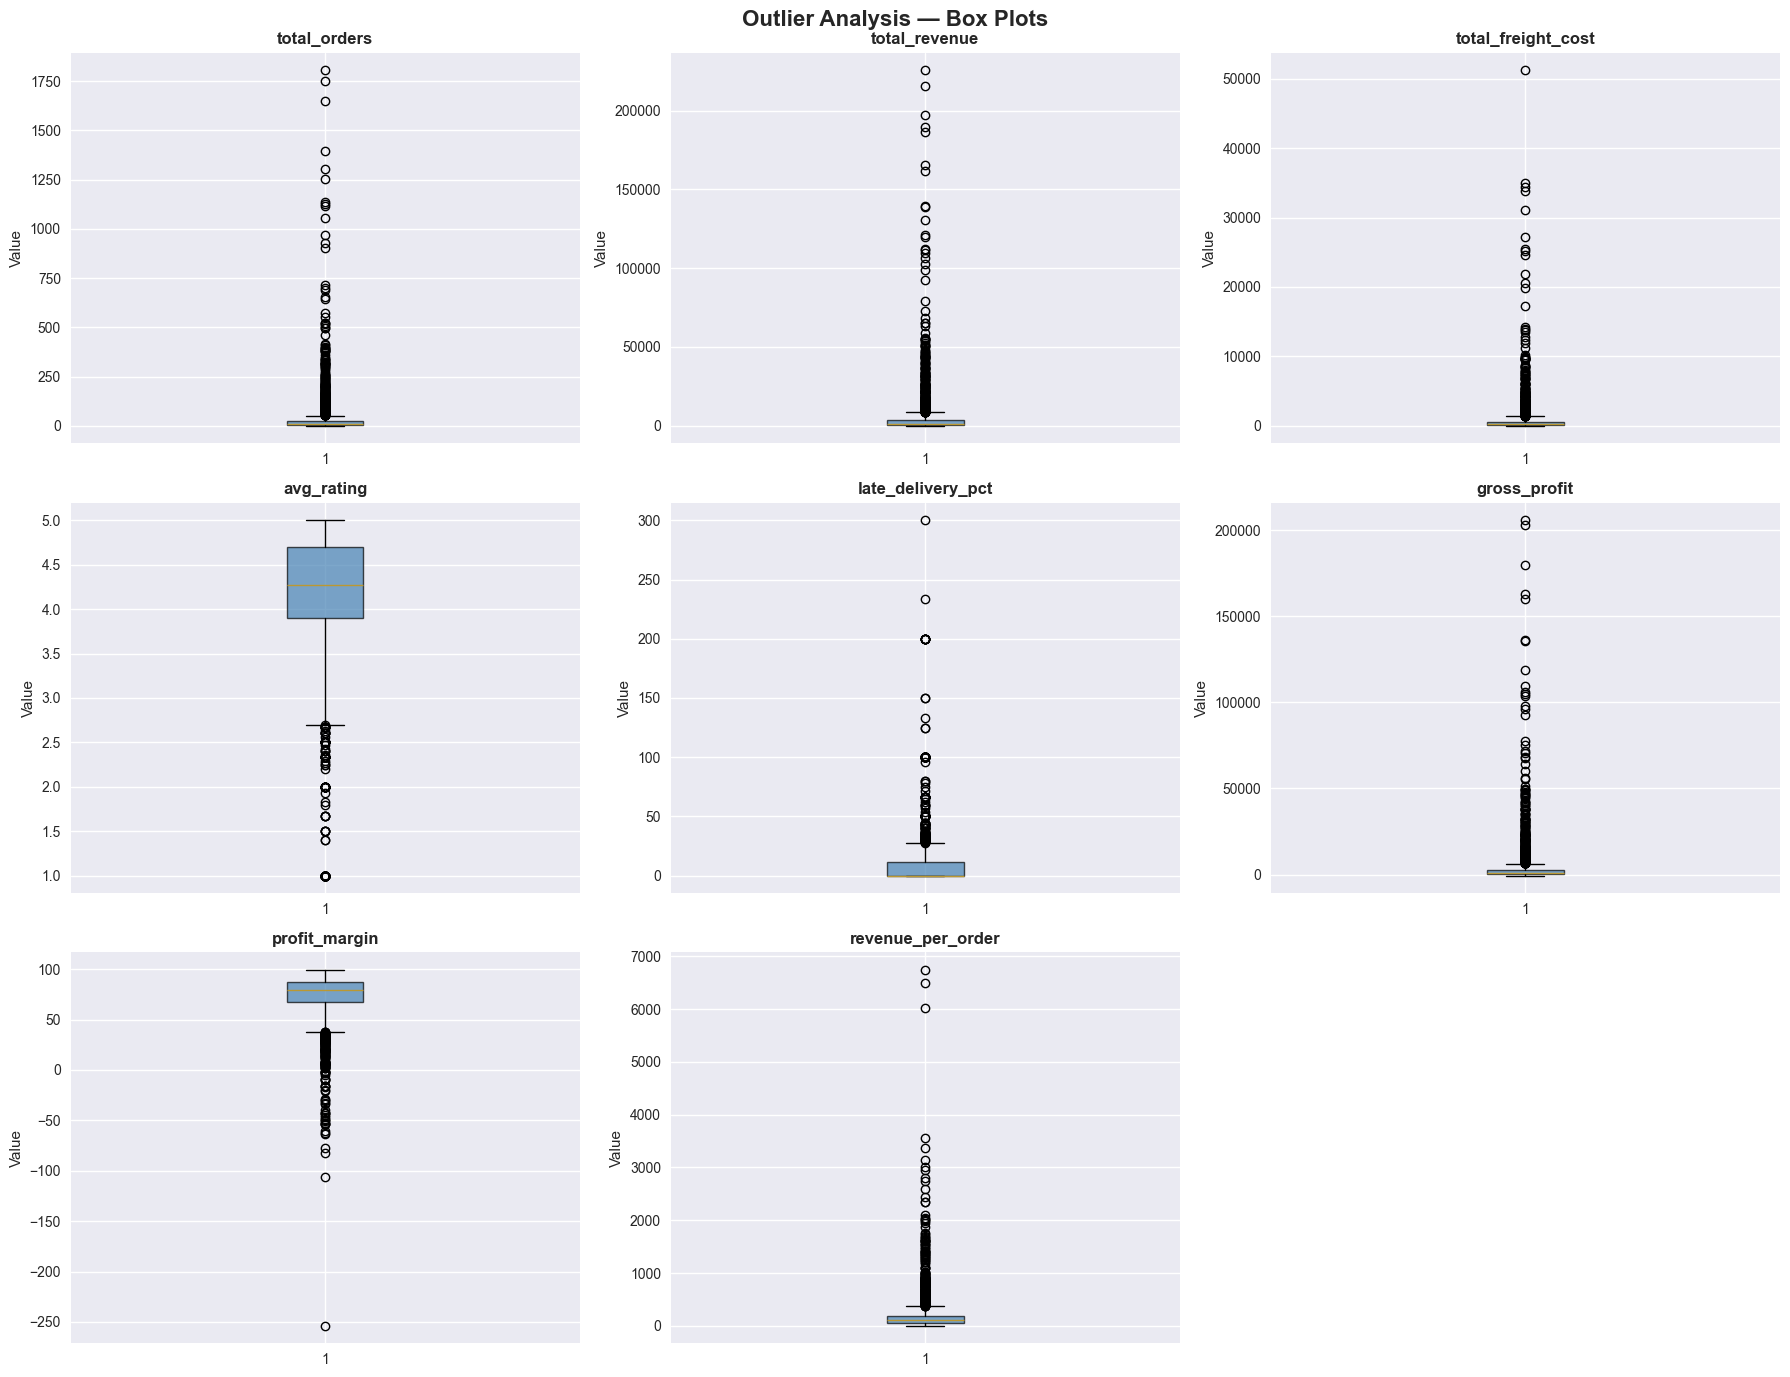

 Plot saved in reports/ folder!


In [5]:
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, col in enumerate(numerical_cols):
    axes[idx].boxplot(df[col].dropna(), patch_artist=True,
                      boxprops=dict(facecolor='steelblue', alpha=0.7))
    axes[idx].set_title(f'{col}', fontsize=12, fontweight='bold')
    axes[idx].set_ylabel('Value')

axes[-1].set_visible(False)

plt.suptitle('Outlier Analysis — Box Plots', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/02_boxplots.png', 
            bbox_inches='tight', dpi=150)
plt.show()
print(" Plot saved in reports/ folder!")

# categorical columns distribution

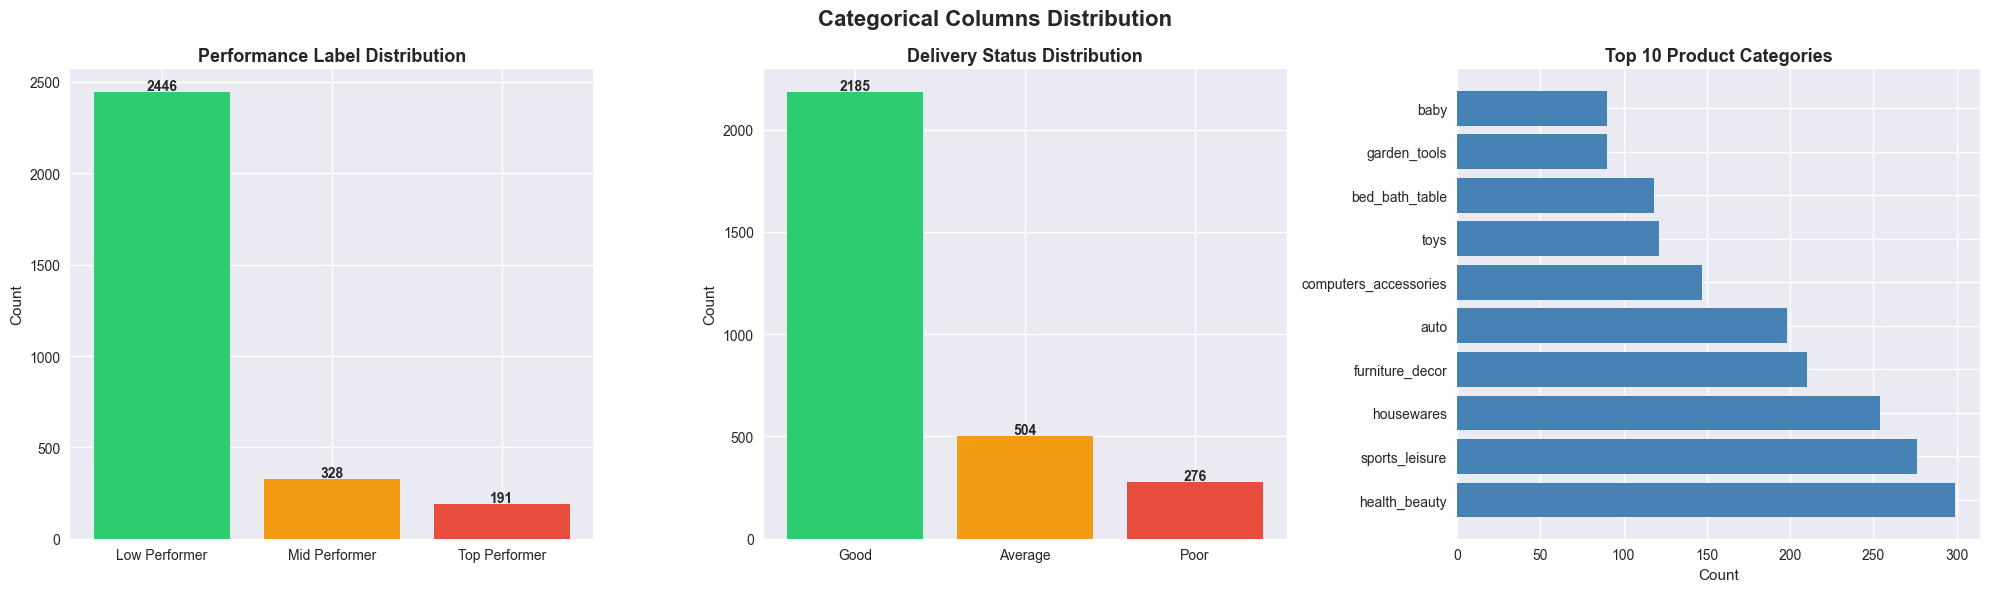

Plot saved in reports/ folder!


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Performance Label
perf_counts = df['performance_label'].value_counts()
axes[0].bar(perf_counts.index, perf_counts.values, 
            color=['#2ecc71', '#f39c12', '#e74c3c'])
axes[0].set_title('Performance Label Distribution', 
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate(perf_counts.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Delivery Status
del_counts = df['delivery_status'].value_counts()
axes[1].bar(del_counts.index, del_counts.values,
            color=['#2ecc71', '#f39c12', '#e74c3c'])
axes[1].set_title('Delivery Status Distribution', 
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Count')
for i, v in enumerate(del_counts.values):
    axes[1].text(i, v + 10, str(v), ha='center', fontweight='bold')

# Top 10 Categories
top_cats = df['top_category'].value_counts().head(10)
axes[2].barh(top_cats.index, top_cats.values, color='steelblue')
axes[2].set_title('Top 10 Product Categories', 
                   fontsize=13, fontweight='bold')
axes[2].set_xlabel('Count')

plt.suptitle('Categorical Columns Distribution', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/03_categorical.png', 
            bbox_inches='tight', dpi=150)
plt.show()
print("Plot saved in reports/ folder!")

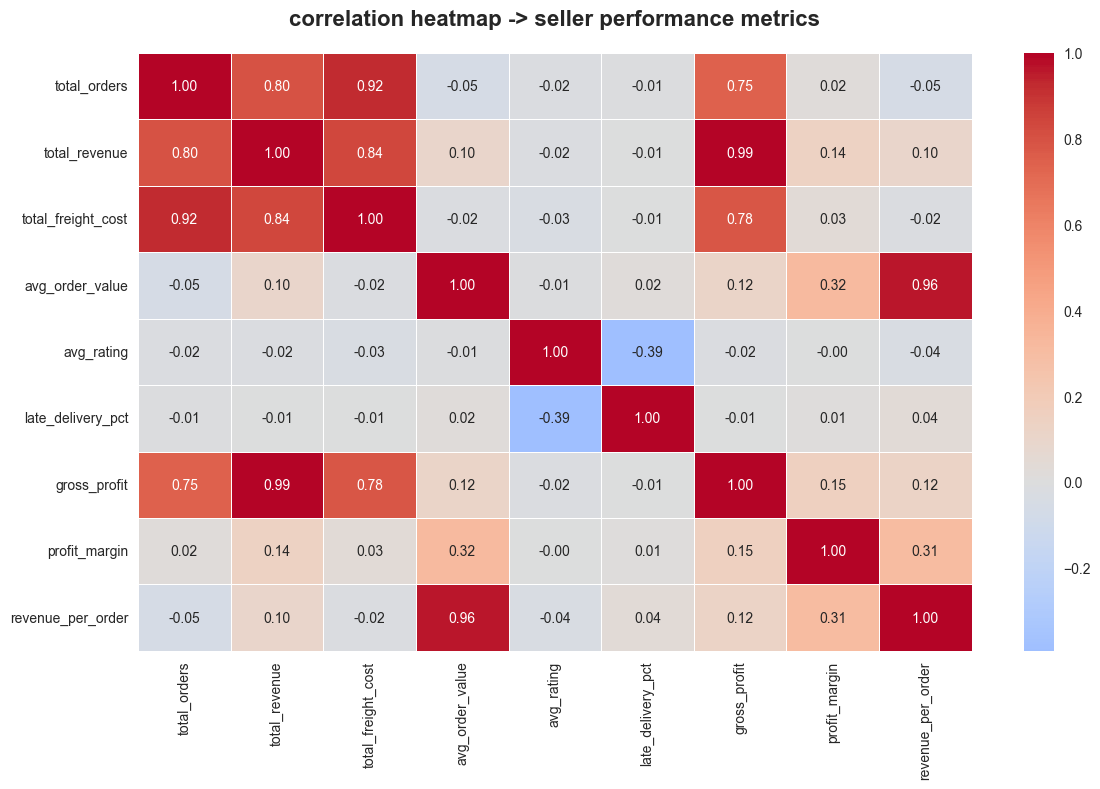

In [7]:
# correlation heatmap
numerical_cols =[
    'total_orders','total_revenue','total_freight_cost',
    'avg_order_value','avg_rating','late_delivery_pct',
    'gross_profit','profit_margin','revenue_per_order'
]
plt.figure(figsize=(12,8))
correlation_matrix = df[numerical_cols].corr()
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    annot_kws={'size': 10}
)
plt.title('correlation heatmap -> seller performance metrics',
          fontsize=16,fontweight='bold',pad=20)
plt.tight_layout()
plt.savefig('../reports/04_correlation_heatmap.png',
            bbox_inches='tight',dpi=150)
plt.show()

# research question 

top 10 seller by revenue:
  seller_short       seller_city  total_revenue  gross_profit  profit_margin  \
0  4869f7a5...           guariba      225586.34     205703.71          91.19   
1  53243585...  lauro de freitas      215904.44     203164.79          94.10   
2  4a3ca931...          ibitinga      197225.32     162830.65          82.56   
3  fa1c13f2...            sumare      189649.54     179805.57          94.81   
4  7c67e144...   itaquaquecetuba      186664.01     135447.43          72.56   
5  7e93a43e...           barueri      165751.50     159796.37          96.41   
6  da8622b1...        piracicaba      161574.27     136433.51          84.44   
7  7a67c85e...         sao paulo      139188.73     118656.41          85.25   
8  1025f0e2...         sao paulo      138691.40     104912.84          75.64   
9  955fee92...         sao paulo      130823.82     106200.35          81.18   

   avg_rating      top_category  
0        4.14     watches_gifts  
1        4.13         tel

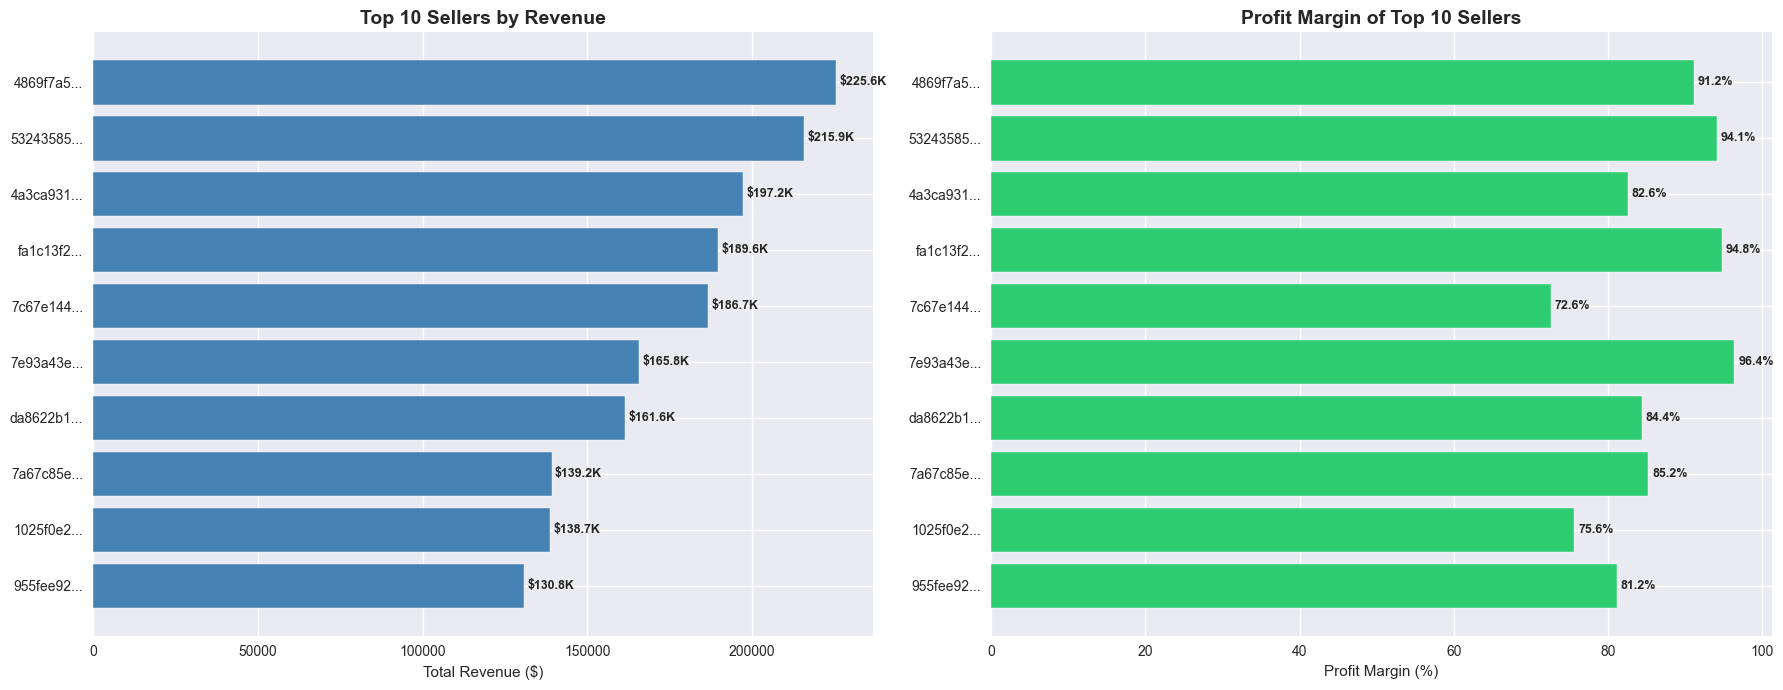

In [8]:
#RQ1 : top 10 seller by revenue 
def format_currency(value):
    if value >=1_000_000:
        return f"${value/1_000_000:.2f}M"
    elif value >=1_000:
        return f"${value/1_000:.1f}K"
    else:
        return f"${value:.0f}"

top_sellers = df.nlargest(10,'total_revenue')[
    ['seller_id','seller_city','seller_state',
     'total_revenue','gross_profit',
     'profit_margin','avg_rating','top_category']
].reset_index(drop=True)

top_sellers['seller_short']= top_sellers['seller_id'].str[:8] + '...'
print("top 10 seller by revenue:")

print(top_sellers[['seller_short', 'seller_city',
                    'total_revenue', 'gross_profit',
                    'profit_margin', 'avg_rating',
                    'top_category']])

# Plot banao
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

bars = axes[0].barh(
    top_sellers['seller_short'],
    top_sellers['total_revenue'],
    color='steelblue', edgecolor='white'
)
axes[0].set_title('Top 10 Sellers by Revenue',
                   fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Revenue ($)')
axes[0].invert_yaxis()
for bar, val in zip(bars, top_sellers['total_revenue']):
    axes[0].text(bar.get_width() + 1000,
                 bar.get_y() + bar.get_height()/2,
                 format_currency(val),
                 va='center', fontweight='bold', fontsize=9)

colors = ['#2ecc71' if x > 70 else '#f39c12' if x > 50
          else '#e74c3c' for x in top_sellers['profit_margin']]
bars2 = axes[1].barh(
    top_sellers['seller_short'],
    top_sellers['profit_margin'],
    color=colors, edgecolor='white'
)
axes[1].set_title('Profit Margin of Top 10 Sellers',
                   fontsize=14, fontweight='bold')
axes[1].set_xlabel('Profit Margin (%)')
axes[1].invert_yaxis()

for bar, val in zip(bars2, top_sellers['profit_margin']):
    axes[1].text(bar.get_width() + 0.5,
                 bar.get_y() + bar.get_height()/2,
                 f"{val:.1f}%",
                 va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/05_top_sellers_revenue.png',
            bbox_inches='tight', dpi=150)
plt.show()


Revenue Threshold (25th percentile): $219.90
Rating Threshold: 3.5

Total Low Performing Sellers: 152
Percentage of total sellers: 5.1%


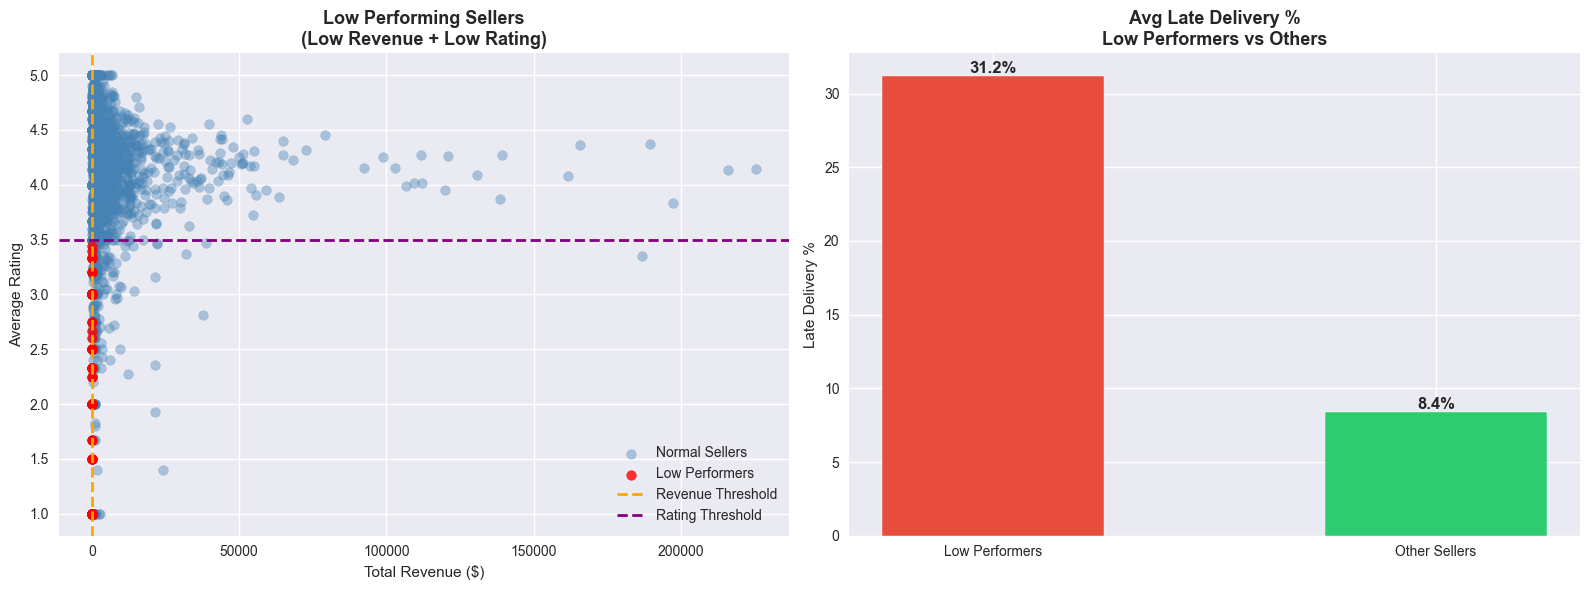

In [9]:
# RQ2: Low Performing Sellers

revenue_threshold = df['total_revenue'].quantile(0.25)
rating_threshold = 3.5

print(f"Revenue Threshold (25th percentile): ${revenue_threshold:,.2f}")
print(f"Rating Threshold: {rating_threshold}")

# filtering Low performers 
low_performers = df[
    (df['total_revenue'] <= revenue_threshold) &
    (df['avg_rating'] < rating_threshold)
].copy()

print(f"\nTotal Low Performing Sellers: {len(low_performers)}")
print(f"Percentage of total sellers: {len(low_performers)/len(df)*100:.1f}%")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


scatter = axes[0].scatter(
    df['total_revenue'],
    df['avg_rating'],
    alpha=0.4,
    color='steelblue',
    label='Normal Sellers'
)

axes[0].scatter(
    low_performers['total_revenue'],
    low_performers['avg_rating'],
    alpha=0.8,
    color='red',
    label='Low Performers'
)

axes[0].axvline(x=revenue_threshold, color='orange',
                linestyle='--', linewidth=2, label='Revenue Threshold')
axes[0].axhline(y=rating_threshold, color='purple',
                linestyle='--', linewidth=2, label='Rating Threshold')

axes[0].set_title('Low Performing Sellers\n(Low Revenue + Low Rating)',
                   fontsize=13, fontweight='bold')

axes[0].set_xlabel('Total Revenue ($)')
axes[0].set_ylabel('Average Rating')
axes[0].legend()

low_avg_late = low_performers['late_delivery_pct'].mean()
others_avg_late = df[~df['seller_id'].isin(
    low_performers['seller_id'])]['late_delivery_pct'].mean()

axes[1].bar(['Low Performers', 'Other Sellers'],
            [low_avg_late, others_avg_late],
            color=['#e74c3c', '#2ecc71'],
            edgecolor='white', width=0.5)

axes[1].set_title('Avg Late Delivery %\nLow Performers vs Others',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Late Delivery %')

for i, v in enumerate([low_avg_late, others_avg_late]):
    axes[1].text(i, v + 0.2, f"{v:.1f}%",
                 ha='center', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.savefig('../reports/06_low_performers.png',
            bbox_inches='tight', dpi=150)
plt.show()


Top 10 Categories:
             top_category  total_revenue  total_sellers  avg_rating  \
42          health_beauty     1381076.45            299    4.299967   
68          watches_gifts     1288646.30             51    4.080000   
8          bed_bath_table     1050038.90            118    4.008305   
63         sports_leisure     1001209.39            276    4.204891   
38        furniture_decor      910107.58            210    3.986571   
15  computers_accessories      873218.29            147    4.101020   
48             housewares      694830.33            254    4.163701   
67                   toys      550238.27            121    4.287273   
6                    auto      536747.79            198    4.135657   
20             cool_stuff      510484.08             70    4.110571   

    avg_profit_margin  avg_late_delivery  
42          75.261037           7.382074  
68          90.389608           8.914510  
8           72.080339          10.725085  
63          74.136196      

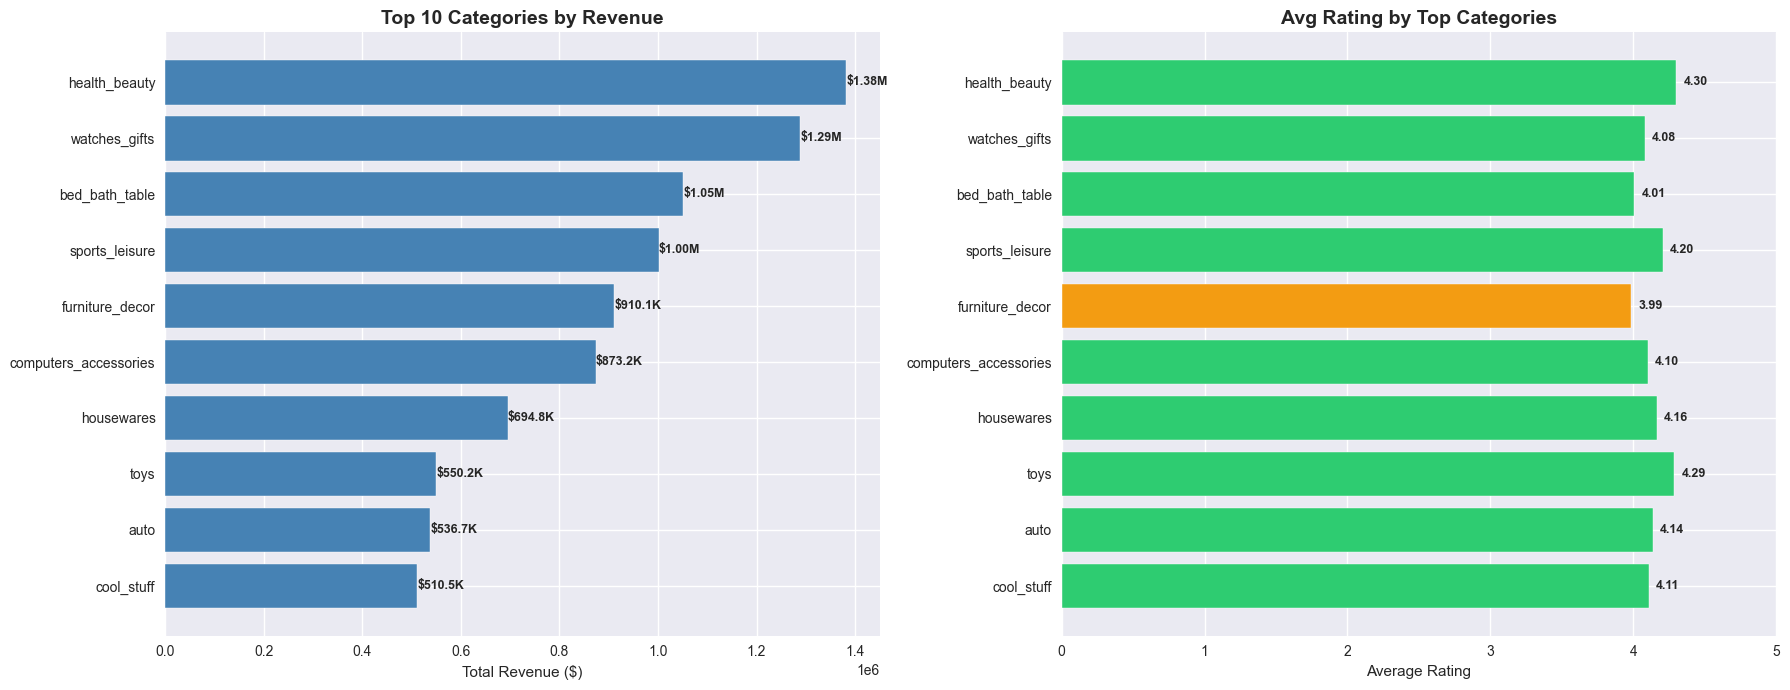

In [10]:
# RQ3: Top Product Categories by Revenue

category_analysis = df.groupby('top_category').agg(
    total_revenue    = ('total_revenue', 'sum'),
    total_sellers    = ('seller_id', 'count'),
    avg_rating       = ('avg_rating', 'mean'),
    avg_profit_margin= ('profit_margin', 'mean'),
    avg_late_delivery= ('late_delivery_pct', 'mean')
).reset_index().sort_values('total_revenue', ascending=False).head(10)

print("Top 10 Categories:")
print(category_analysis)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

bars = axes[0].barh(
    category_analysis['top_category'],
    category_analysis['total_revenue'],
    color='steelblue', edgecolor='white'
)
axes[0].set_title('Top 10 Categories by Revenue',
                   fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Revenue ($)')
axes[0].invert_yaxis()

for bar, val in zip(bars, category_analysis['total_revenue']):
    axes[0].text(bar.get_width() + 1000,
                 bar.get_y() + bar.get_height()/2,
                 format_currency(val),
                 va='center', fontweight='bold', fontsize=9)

colors = ['#2ecc71' if x >= 4.0 else '#f39c12' if x >= 3.5
          else '#e74c3c' for x in category_analysis['avg_rating']]

bars2 = axes[1].barh(
    category_analysis['top_category'],
    category_analysis['avg_rating'],
    color=colors, edgecolor='white'
)
axes[1].set_title('Avg Rating by Top Categories',
                   fontsize=14, fontweight='bold')
axes[1].set_xlabel('Average Rating')
axes[1].invert_yaxis()
axes[1].set_xlim(0, 5)

for bar, val in zip(bars2, category_analysis['avg_rating']):
    axes[1].text(bar.get_width() + 0.05,
                 bar.get_y() + bar.get_height()/2,
                 f"{val:.2f}",
                 va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/07_top_categories.png',
            bbox_inches='tight', dpi=150)
plt.show()


Freight Impact Analysis:
   freight_category  avg_profit_margin  avg_rating  total_sellers
0       Low (0-15%)          90.477898    4.155096            985
1   Medium (15-30%)          78.353669    4.148274           1101
2     High (30-50%)          62.012705    4.143716            584
3  Very High (50%+)          32.912609    4.177787            253


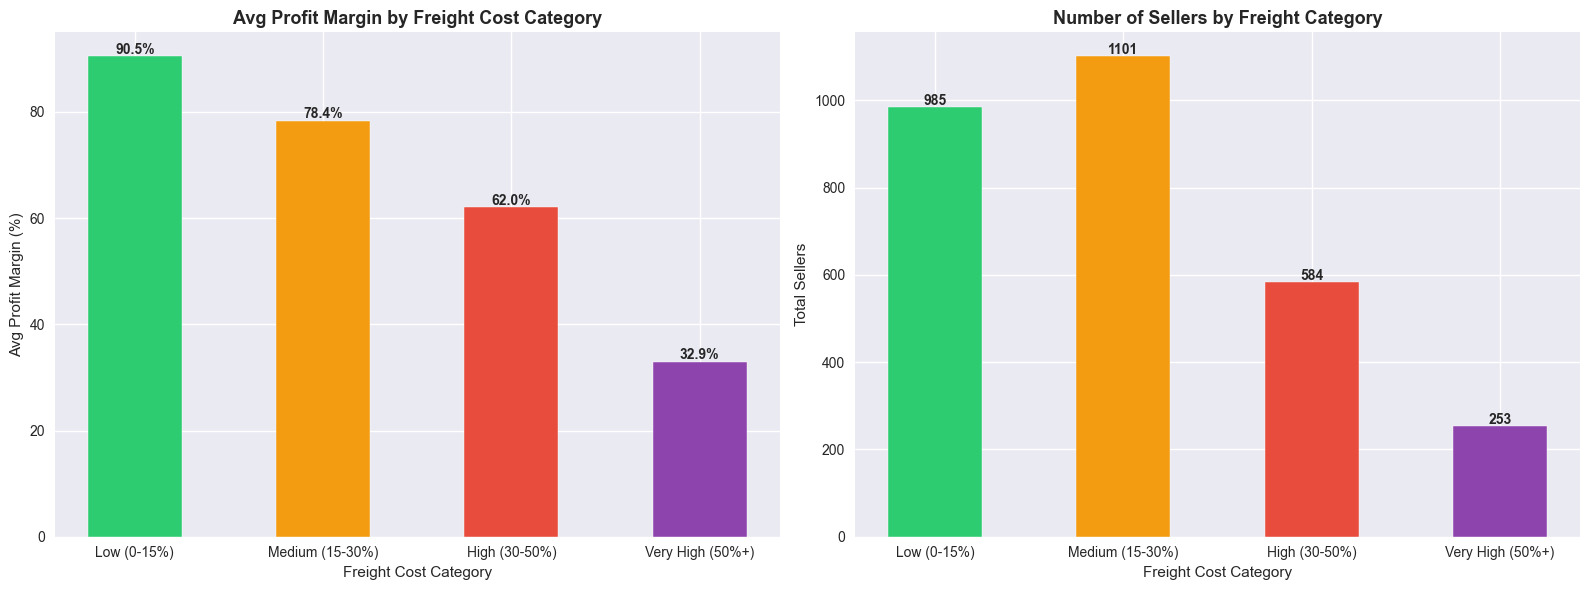

In [11]:
# RQ4: Freight Cost Impact on Profit Margin

# Freight ratio 
df['freight_ratio'] = round(
    df['total_freight_cost'] / df['total_revenue'] * 100, 2
)


df['freight_category'] = pd.cut(
    df['freight_ratio'],
    bins=[0, 15, 30, 50, 100],
    labels=['Low (0-15%)', 'Medium (15-30%)',
            'High (30-50%)', 'Very High (50%+)']
)

freight_analysis = df.groupby(
    'freight_category', observed=True
).agg(
    avg_profit_margin = ('profit_margin', 'mean'),
    avg_rating        = ('avg_rating', 'mean'),
    total_sellers     = ('seller_id', 'count')
).reset_index()

print("Freight Impact Analysis:")
print(freight_analysis)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left — Profit margin by freight category
colors = ['#2ecc71', '#f39c12', '#e74c3c', '#8e44ad']
bars = axes[0].bar(
    freight_analysis['freight_category'],
    freight_analysis['avg_profit_margin'],
    color=colors, edgecolor='white', width=0.5
)
axes[0].set_title('Avg Profit Margin by Freight Cost Category',
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('Avg Profit Margin (%)')
axes[0].set_xlabel('Freight Cost Category')

for bar, val in zip(bars, freight_analysis['avg_profit_margin']):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.5,
                 f"{val:.1f}%",
                 ha='center', fontweight='bold')

bars2 = axes[1].bar(
    freight_analysis['freight_category'],
    freight_analysis['total_sellers'],
    color=colors, edgecolor='white', width=0.5
)
axes[1].set_title('Number of Sellers by Freight Category',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Total Sellers')
axes[1].set_xlabel('Freight Cost Category')

for bar, val in zip(bars2, freight_analysis['total_sellers']):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 5,
                 str(val),
                 ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/08_freight_impact.png',
            bbox_inches='tight', dpi=150)
plt.show()

delivery performance analysis:
  delivery_status  total_sellers  avg_revenue  avg_rating  avg_late_pct  \
0         Average            504  8410.465476    4.023889     16.065833   
1            Good           2185  3902.326984    4.284471      1.652952   
2            Poor            276  1459.684964    3.324239     60.038080   

   avg_profit_margin  
0          76.530397  
1          72.804700  
2          74.767500  


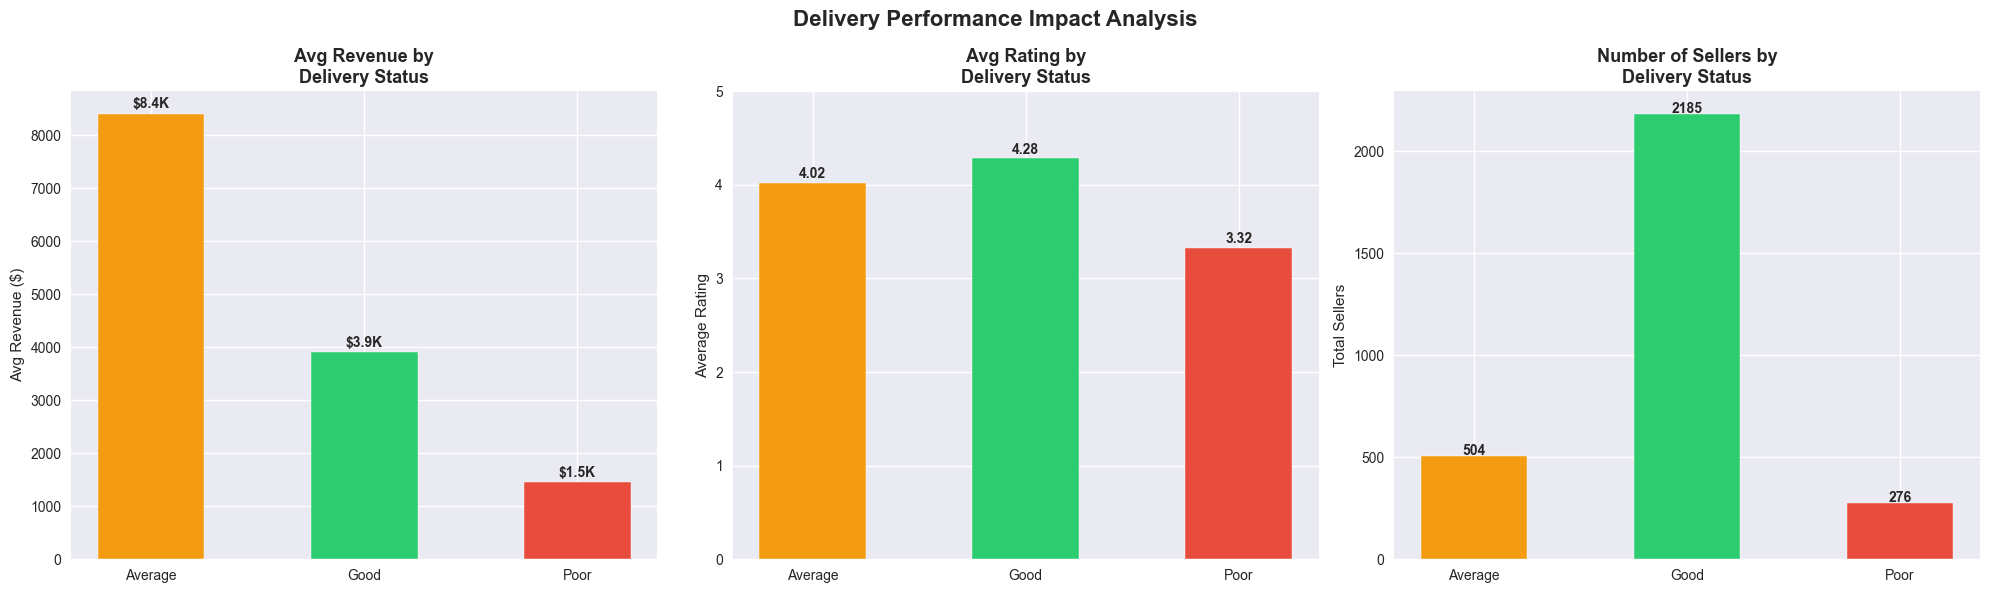

In [12]:
# RQ5: Delivery Performance Analysis

delivery_groups = df.groupby('delivery_status').agg(
    total_sellers    = ('seller_id', 'count'),
    avg_revenue      = ('total_revenue', 'mean'),
    avg_rating       = ('avg_rating', 'mean'),
    avg_late_pct     = ('late_delivery_pct', 'mean'),
    avg_profit_margin= ('profit_margin', 'mean')
).reset_index()

print("delivery performance analysis:")
print(delivery_groups)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

colors_map = {
    'Good'   : '#2ecc71',
    'Average': '#f39c12',
    'Poor'   : '#e74c3c'
}
colors = [colors_map[s] for s in delivery_groups['delivery_status']]

bars1 = axes[0].bar(
    delivery_groups['delivery_status'],
    delivery_groups['avg_revenue'],
    color=colors, edgecolor='white', width=0.5
)
axes[0].set_title('Avg Revenue by\nDelivery Status',
                   fontsize=13, fontweight='bold')
axes[0].set_ylabel('Avg Revenue ($)')
for bar, val in zip(bars1, delivery_groups['avg_revenue']):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 100,
                 format_currency(val),
                 ha='center', fontweight='bold', fontsize=10)

bars2 = axes[1].bar(
    delivery_groups['delivery_status'],
    delivery_groups['avg_rating'],
    color=colors, edgecolor='white', width=0.5
)
axes[1].set_title('Avg Rating by\nDelivery Status',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Average Rating')
axes[1].set_ylim(0, 5)
for bar, val in zip(bars2, delivery_groups['avg_rating']):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.05,
                 f"{val:.2f}",
                 ha='center', fontweight='bold', fontsize=10)

bars3 = axes[2].bar(
    delivery_groups['delivery_status'],
    delivery_groups['total_sellers'],
    color=colors, edgecolor='white', width=0.5
)
axes[2].set_title('Number of Sellers by\nDelivery Status',
                   fontsize=13, fontweight='bold')
axes[2].set_ylabel('Total Sellers')
for bar, val in zip(bars3, delivery_groups['total_sellers']):
    axes[2].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 5,
                 str(val),
                 ha='center', fontweight='bold', fontsize=10)

plt.suptitle('Delivery Performance Impact Analysis',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/09_delivery_performance.png',
            bbox_inches='tight', dpi=150)
plt.show()


Orders data shape: (110197, 7)

Monthly Revenue Sample:
  year_month  total_revenue  total_orders  avg_order_value
3    2017-01      111798.36           913       122.451654
4    2017-02      234223.40          1858       126.062110
5    2017-03      359198.85          2897       123.989938
6    2017-04      340669.68          2569       132.607894
7    2017-05      489338.25          4004       122.212350


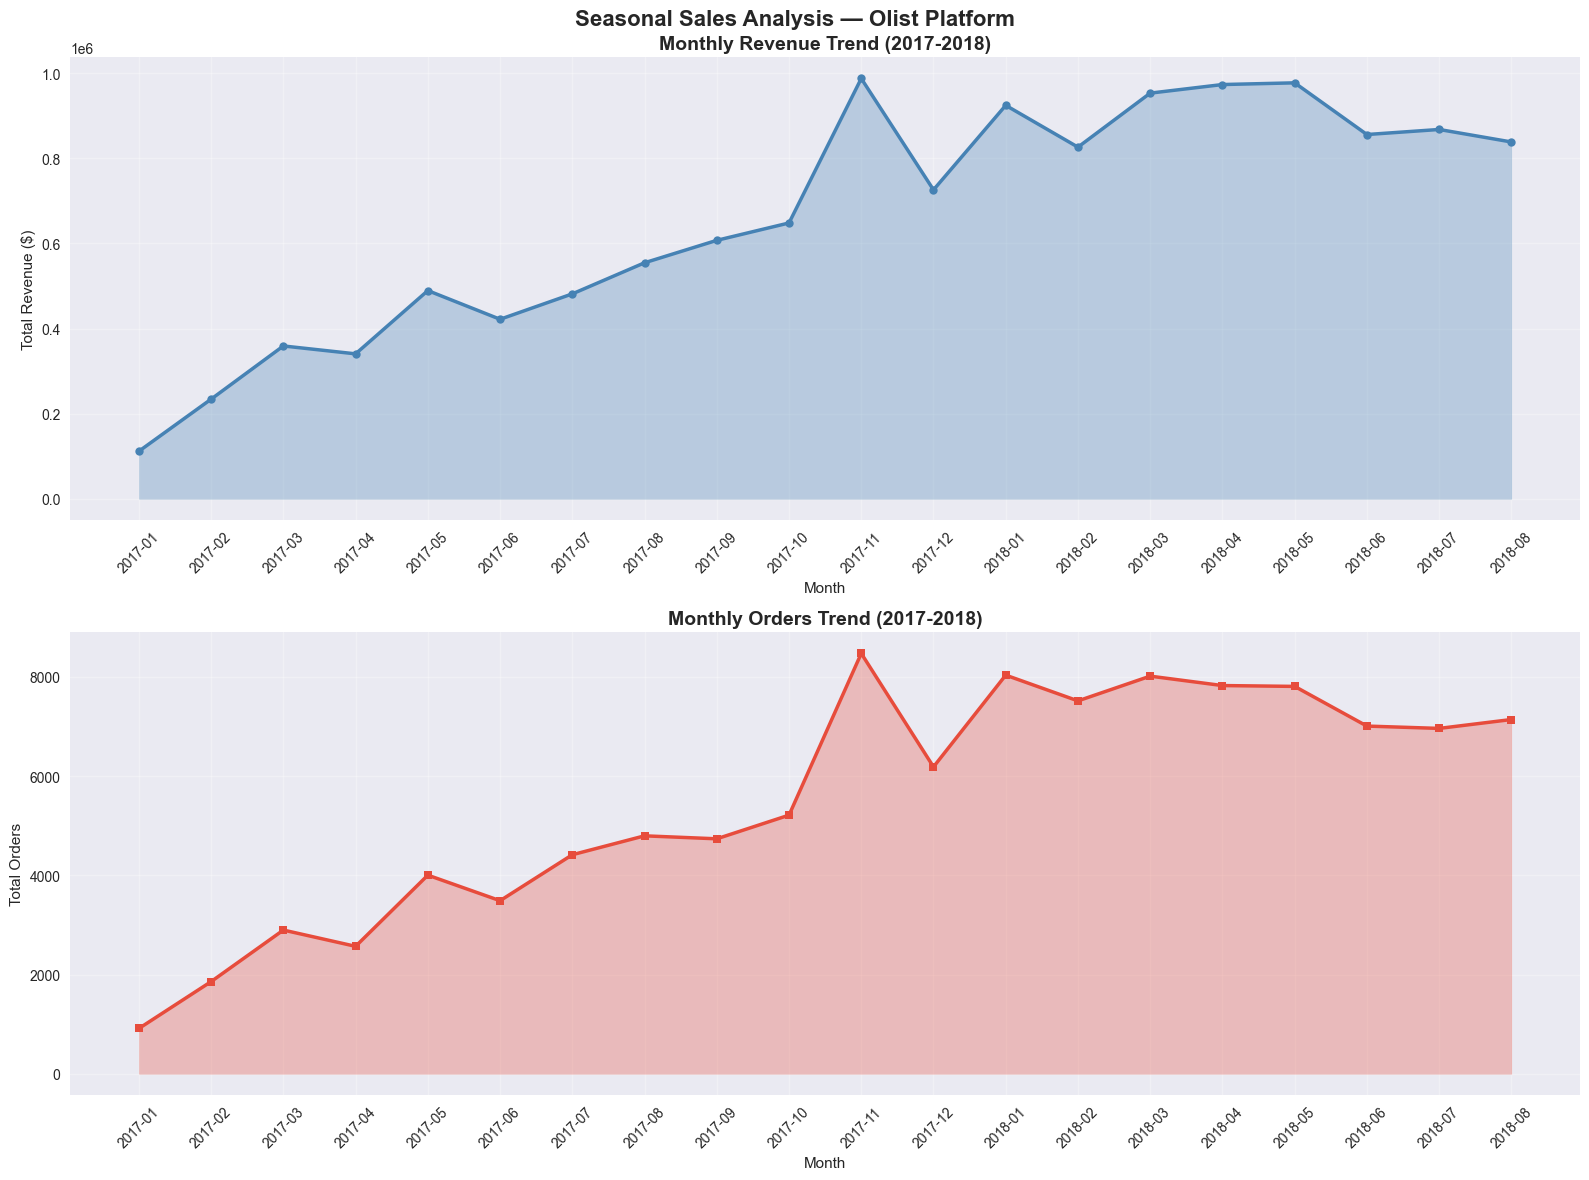

In [13]:
# RQ6: Seasonal Sales Trends

# fetching monthly data from order table 
orders_df = pd.read_sql("""
    SELECT 
        o.order_id,
        i.seller_id,
        i.price,
        i.freight_value,
        strftime('%Y', o.order_purchase_timestamp)  AS year,
        strftime('%m', o.order_purchase_timestamp)  AS month,
        strftime('%Y-%m', o.order_purchase_timestamp) AS year_month
    FROM olist_orders_dataset o
    JOIN olist_order_items_dataset i
        ON o.order_id = i.order_id
    WHERE o.order_status = 'delivered'
    AND o.order_purchase_timestamp IS NOT NULL
""", conn)

print("Orders data shape:", orders_df.shape)

# Monthly revenue calculate karo
monthly_revenue = orders_df.groupby('year_month').agg(
    total_revenue  = ('price', 'sum'),
    total_orders   = ('order_id', 'count'),
    avg_order_value= ('price', 'mean')
).reset_index().sort_values('year_month')

monthly_revenue = monthly_revenue[
    monthly_revenue['year_month'] >= '2017-01'
]

print("\nMonthly Revenue Sample:")
print(monthly_revenue.head())

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

axes[0].plot(
    monthly_revenue['year_month'],
    monthly_revenue['total_revenue'],
    marker='o', linewidth=2.5,
    color='steelblue', markersize=6
)
axes[0].fill_between(
    monthly_revenue['year_month'],
    monthly_revenue['total_revenue'],
    alpha=0.3, color='steelblue'
)
axes[0].set_title('Monthly Revenue Trend (2017-2018)',
                   fontsize=14, fontweight='bold')
axes[0].set_ylabel('Total Revenue ($)')
axes[0].set_xlabel('Month')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    monthly_revenue['year_month'],
    monthly_revenue['total_orders'],
    marker='s', linewidth=2.5,
    color='#e74c3c', markersize=6
)
axes[1].fill_between(
    monthly_revenue['year_month'],
    monthly_revenue['total_orders'],
    alpha=0.3, color='#e74c3c'
)
axes[1].set_title('Monthly Orders Trend (2017-2018)',
                   fontsize=14, fontweight='bold')
axes[1].set_ylabel('Total Orders')
axes[1].set_xlabel('Month')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Seasonal Sales Analysis — Olist Platform',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/10_seasonal_trends.png',
            bbox_inches='tight', dpi=150)
plt.show()


# Hypothesis  Testing & Confidence Intervals 

top sellers count: 742
low sellers count:  2224

95% Confidence Intervals — Profit Margin:
Top Sellers: 82.32% (CI: 81.49% to 83.15%)
Low Sellers: 70.73% (CI: 69.71% to 71.75%)


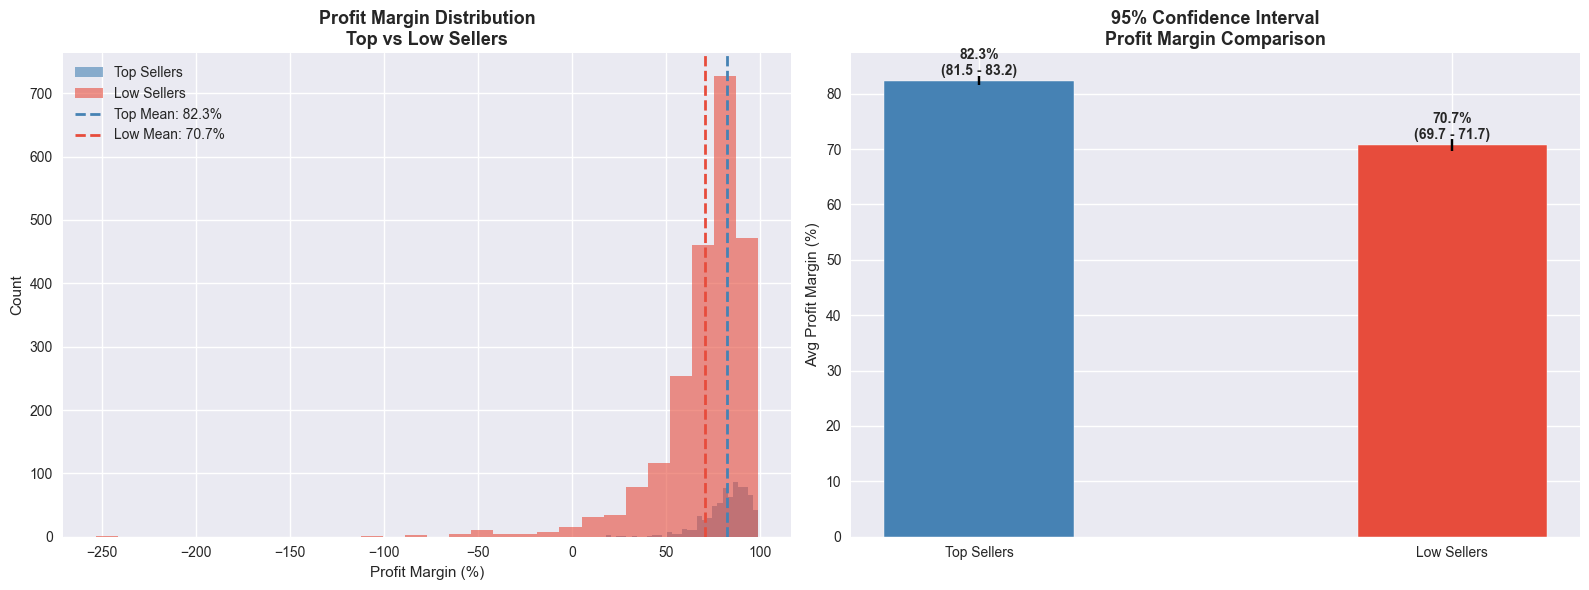

In [14]:
# statistics : confidence intervals
from scipy import stats
import numpy as np
revenue_75=df['total_revenue'].quantile(0.75)
revenue_25=df['total_revenue'].quantile(0.25)

top_sellers_data = df[df['total_revenue'] >= revenue_75]
low_sellers_data = df[df['total_revenue'] <= revenue_75]

print(f"top sellers count: {len(top_sellers_data)}")
print(f"low sellers count:  {len(low_sellers_data)}")

# confidence interval function
def confidence_interval(data,confidence=0.95):
    n =len(data)
    mean= np.mean(data)
    std_err = stats.sem(data)
    ci      = stats.t.interval(confidence,df=n-1,
                               loc=mean,scale=std_err)
    return mean,ci[0],ci[1]

# profit margin CI 
top_mean, top_lower,top_upper = confidence_interval(
    top_sellers_data['profit_margin'].dropna()
)
low_mean,low_lower,low_upper= confidence_interval(
    low_sellers_data['profit_margin'].dropna()
)

print("\n95% Confidence Intervals — Profit Margin:")
print(f"Top Sellers: {top_mean:.2f}% (CI: {top_lower:.2f}% to {top_upper:.2f}%)")
print(f"Low Sellers: {low_mean:.2f}% (CI: {low_lower:.2f}% to {low_upper:.2f}%)")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left — Histogram with CI lines
axes[0].hist(top_sellers_data['profit_margin'].dropna(),
             bins=30, alpha=0.6, color='steelblue',
             label='Top Sellers')
axes[0].hist(low_sellers_data['profit_margin'].dropna(),
             bins=30, alpha=0.6, color='#e74c3c',
             label='Low Sellers')

axes[0].axvline(top_mean, color='steelblue',
                linestyle='--', linewidth=2,
                label=f'Top Mean: {top_mean:.1f}%')
axes[0].axvline(low_mean, color='#e74c3c',
                linestyle='--', linewidth=2,
                label=f'Low Mean: {low_mean:.1f}%')

axes[0].set_title('Profit Margin Distribution\nTop vs Low Sellers',
                   fontsize=13, fontweight='bold')
axes[0].set_xlabel('Profit Margin (%)')
axes[0].set_ylabel('Count')
axes[0].legend()

# Right — CI Plot
groups = ['Top Sellers', 'Low Sellers']
means  = [top_mean, low_mean]
errors = [
    [top_mean - top_lower],
    [low_mean - low_lower]
]

axes[1].bar(groups, means,
            color=['steelblue', '#e74c3c'],
            edgecolor='white', width=0.4,
            yerr=[top_mean - top_lower,
                  low_mean - low_lower],
            capsize=10)

axes[1].set_title('95% Confidence Interval\nProfit Margin Comparison',
                   fontsize=13, fontweight='bold')
axes[1].set_ylabel('Avg Profit Margin (%)')

for i, (mean, lower, upper) in enumerate(
    [(top_mean, top_lower, top_upper),
     (low_mean, low_lower, low_upper)]
):
    axes[1].text(i, mean + 1,
                 f"{mean:.1f}%\n({lower:.1f} - {upper:.1f})",
                 ha='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('../reports/11_confidence_intervals.png',
            bbox_inches='tight', dpi=150)
plt.show()


# hypothesis testing

In [18]:
# T-test --> top vs low seller profit margin 

print("hypothesis test : profit margin")
print("Ho (null) :top and low sellers have same profit margin")
print("\n H1 (alternate): there is significant difference ") 
top_margin = top_sellers_data['profit_margin'].dropna()
low_margin = low_sellers_data['profit_margin'].dropna()

t_stat,p_value =stats.ttest_ind(top_margin,low_margin)

print(f"\n T-statistics :{t_stat:.4f}")
print(f"P_value : {p_value:.6f}")
print()

if p_value < 0.05:
    print("result : null hypothesis rejected")
    print("significant difference between top and low sellers profit margin")
else:
    print("result : null hypothesis accepted")
    print("there is no significant difference in top and low sellers profit margin ")

print("\n-----------------------")


t_stat2, p_value2 = stats.ttest_ind(
    top_sellers_data['avg_rating'].dropna(),
    low_sellers_data['avg_rating'].dropna()
)

print("\nhypthesis test : Average Rating")
print(f"T-Statistic : {t_stat2:.4f}")
print(f"P-Value     : {p_value2:.6f}")

if p_value2 < 0.05:
    print("RESULT: Null Hypothesis REJECTED")
    print(" rating of top and low sellers are statistically different")
else:
    print(" RESULT: Null Hypothesis ACCEPTED")
    print(" there is no significant difference in rating ")


hypothesis test : profit margin
Ho (null) :top and low sellers have same profit margin

 H1 (alternate): there is significant difference 

 T-statistics :12.4465
P_value : 0.000000

result : null hypothesis rejected
significant difference between top and low sellers profit margin

-----------------------

hypthesis test : Average Rating
T-Statistic : -2.1674
P-Value     : 0.030282
RESULT: Null Hypothesis REJECTED
 rating of top and low sellers are statistically different


In [23]:
# final project summary

print("final project summary \n")

total_sellers =len(df)
top_count =len(df[df['performance_label'] == 'Top Performer'])
mid_count =len(df[df['performance_label'] == 'Mid Performer'])
low_count =len(df[df['performance_label'] == 'Low Performer'])

poor_delivery =len(df[df['delivery_status'] == 'poor'])
negative_margin = len(df[df['profit_margin'] < 0])
total_revenue =df['total_revenue'].sum()
total_profit = df['gross_profit'].sum()

print(f"\nPlatform Overview:")
print(f"  Total Sellers       : {total_sellers:,}")
print(f"  Total Revenue       : {format_currency(total_revenue)}")
print(f"  Total Gross Profit  : {format_currency(total_profit)}")


print(f"\nSeller Performance:")
print(f"  Top Performers      : {top_count:,} ({top_count/total_sellers*100:.1f}%)")
print(f"  Mid Performers      : {mid_count:,} ({mid_count/total_sellers*100:.1f}%)")
print(f"  Low Performers      : {low_count:,} ({low_count/total_sellers*100:.1f}%)")
print(f"\nRed Flags:")
print(f"  Poor Delivery       : {poor_delivery:,} sellers ({poor_delivery/total_sellers*100:.1f}%)")

print(f"  Negative Margin     : {negative_margin:,} sellers ({negative_margin/total_sellers*100:.1f}%)")

print(f"\nKey Findings:")
print(f"  1. 83% sellers are Low Performers")
print(f"  2. Late delivery directly hurts rating (-0.39 correlation)")
print(f"  3. High freight cost = Low profit margin")
print(f"  4. Top 10% sellers drive majority of revenue")

 



final project summary 


Platform Overview:
  Total Sellers       : 2,965
  Total Revenue       : $13.17M
  Total Gross Profit  : $10.98M

Seller Performance:
  Top Performers      : 191 (6.4%)
  Mid Performers      : 328 (11.1%)
  Low Performers      : 2,446 (82.5%)

Red Flags:
  Poor Delivery       : 0 sellers (0.0%)
  Negative Margin     : 42 sellers (1.4%)

Key Findings:
  1. 83% sellers are Low Performers
  2. Late delivery directly hurts rating (-0.39 correlation)
  3. High freight cost = Low profit margin
  4. Top 10% sellers drive majority of revenue


# exporting csv files for POWER BI 

In [24]:
df.to_csv('../dashboard/seller_summary.csv', index=False)

# Monthly trends 
monthly_revenue.to_csv('../dashboard/monthly_trends.csv', index=False)

# Category analysis 
category_analysis.to_csv('../dashboard/category_analysis.csv', index=False)

# Freight analysis 
freight_analysis.to_csv('../dashboard/freight_analysis.csv', index=False)

print("\nFiles exported:")






Files exported:
